In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

In [ ]:
# [셀 1] 라이브러리 임포트 및 상수 정의
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ===databench 데이터셋 위치===
# DATA = Path("/content/drive/Othercomputers/내 PC/dp4agent/data/bank_exp.parquet")
# COL  = "credit_limit"

# DATA = "/content/drive/Othercomputers/내 PC/dp4agent/data/CardBase.csv"        # 논문 속 데이터셋으로 변경
DATA = Path("data/CardBase.csv")
COL  = "Credit_Limit"

# ===클리핑 바운드===
# L, U = 2000.0, 34000.0

# ===클리핑 없이 진행===
L, U = None, None
EPSILONS = [0.5, 0.75, 1.0, 1.25]

MAXQ      = 500           # 논문 방식이 쿼리를 최대 몇 번까지 반복하는지
REPS      = 50            # 반복 실험 횟수 (커버리지 추정용)

# ===95% 신뢰구간을 산정(ALPHA)했을 때, 그 '상대폭'이 0.01이하(THRESHOLD)로 5번 유지될 때(STREAK) 수렴으로 판단하고 정지===
ALPHA     = 0.05          # 1 - 0.95 신뢰수준 95%
THRESHOLD = 0.01          # 신뢰구간 상대폭이 1% 이하가 되면 정지
STREAK    = 5             # 위의 조건이 연속 5회 유지되어야 정지

# ===반복 실험을 위한 랜덤 함수===
rng = np.random.default_rng(0)

# ===결과는 /content/output에 생성===
Path("outputs").mkdir(exist_ok=True)

In [ ]:
# @title
# [셀 2] 데이터 로딩 및 민감도 계산

# ===databench 데이터셋===
# df = pd.read_parquet(DATA)

# ===KCI 논문 속 데이터셋===
df = pd.read_csv(DATA)

# ===COL  = "credit_limit"===
x  = df[COL].to_numpy(dtype=float)

n         = len(x)                  # 데이터 수: 500개
true_mean = x.mean()

D_PAPER   = x.max() - x.min() / n      # 논문 방식: 전역 max - min

print("==논문과 민감도 비교==")
print(f"n(행 개수)         = {n}")
print(f"데이터 실제 평균값 = {true_mean:,.2f}")

print("======================")
print(f"최대: {x.max()}\t 최소:{x.min()}")
print(f"논문 속 민감도((최대-최소)/N)   = {D_PAPER:,.2f}")

> 시각화 함수 `plot_track()`

In [ ]:
# @title
# [셀 5] 시각화 코드 함수로 감싼 형태
def plot_track(h, title="", true_mean=None, k_stop=None):
    if true_mean is None:
        true_mean = globals().get("true_mean", globals().get("TRUE"))

    # fig는 액자, ax는 실제 그림 그리는 도화지 
    fig, ax = plt.subplots(figsize=(11, 5))
    ok  = h[h.covered == True]
    bad = h[h.covered == False]

    # 데이터를 안정적인 것과 불안정한 것으로 나누어 시각화
    for g, c, lab in [(ok, "tab:blue", "Stable"), (bad, "tab:red", "Unstable")]:
        if len(g):
            # x축 = 샘플 개수(k)
            # y축 = 추정 평균(mean)
            # 오차막대 = 신뢰구간 반폭(moe)
            ax.errorbar(g.k, g["mean"], yerr=g.moe, 
                        fmt="o", ms=3, color=c,
                        ecolor=c, elinewidth=1.2, capsize=0, alpha=0.85, label=lab)

    # 기준선(실제 평균) 그리기
    ax.axhline(true_mean, ls="--", c="green", lw=1.2, label="True Mean")
    if k_stop is not None:
        ax.axvline(k_stop, ls="--", c="k", lw=1, label=f"Converged at {k_stop}")

    r = h.covered.mean()
    ax.set_title(f"{title} | Stable={r:.1%}, Unstable={1-r:.1%}")
    ax.set_xlabel("Query Count"); ax.set_ylabel(COL)
    ax.grid(alpha=0.3); ax.legend()
    plt.tight_layout(); plt.show()

> 실험 함수 `run_live()`

In [ ]:
# @title
# [셀 4-2] run_live() 함수 수정 -> 정지 조건 판단
from scipy import stats

def run_live(delta, eps, seed=0, threshold=THRESHOLD, streak_required=STREAK,
             maxq=MAXQ, verbose=True, verbose_upto=20, every=10):
    """질의를 1개씩 받아 누적 통계를 갱신하고, 정지 조건 충족 시 중단."""
    r = np.random.default_rng(seed)
    b = delta / eps

    s1 = s2 = 0.0          # Σx, Σx²
    streak = 0
    hist = []              # 시각화용 기록

    if verbose:
        print(f"delta={delta:,.4f}  eps={eps}  b={b:,.4f}  "
              f"threshold={threshold}  streak_required={streak_required}\n")

    for k in range(1, maxq + 1):
        v = true_mean + r.laplace(0.0, b)      # 질의 1회 = eps 소모
        s1 += v
        s2 += v * v

        mean = s1 / k
        if k < 2:
            moe = relw = lo = hi = np.nan
            hit = False
        else:
            var  = max((s2 - k * mean**2) / (k - 1), 0.0)
            se   = np.sqrt(var) / np.sqrt(k)
            moe  = stats.t.ppf(1 - ALPHA/2, df=k-1) * se
            lo, hi = mean - moe, mean + moe        # 신뢰구간 하한/상한
            relw = 2 * moe / abs(mean)
            hit  = relw < threshold

        # 신뢰구간 폭 안에 실제 평균(모평균)이 포함되는지 여부 확인
        covered = (abs(mean - true_mean) <= moe) if np.isfinite(moe) else pd.NA
        resp_in = (lo <= v <= hi) if np.isfinite(moe) else pd.NA          # 추가

        streak = streak + 1 if hit else 0
        hist.append((k, v, mean, moe, lo, hi, relw, streak, covered, resp_in))   # resp_in 추가

        # 1~verbose_upto회는 매번, 이후로는 every 배수마다(또는 정지 시점에) 출력
        if verbose and (k <= verbose_upto or k % every == 0 or streak >= streak_required):
            flag = "*" * streak
            mark = "-- " if covered is pd.NA else ("IN " if covered else "OUT")
            ci   = ("         --  ~          -- " if not np.isfinite(moe)
                    else f"{lo:11.2f} ~ {hi:11.2f}")
            print(f"k={k:>4} | resp={v:11.2f} | mean={mean:10.2f} | "
                  f"CI=[{ci}] | moe={moe:9.2f} | relw={relw:8.5f} | "
                  f"{mark} | streak={streak} {flag}")

        if streak >= streak_required:
            if verbose:
                print(f"\n>>> 정지: k={k}, eps_total={eps*k:.2f}, "
                      f"추정={mean:,.2f}, width={moe:.2f}, "
                      f"CI=[{lo:,.2f} ~ {hi:,.2f}]")
            break
    else:
        if verbose:
            print(f"\n>>> {maxq}회 내 미수렴")

    df = pd.DataFrame(hist, columns=["k","resp","mean","moe",
                                     "ci_lo","ci_hi","relw","streak","covered","resp_in"])
    df["covered"] = df["covered"].astype("boolean")
    df["resp_in"] = df["resp_in"].astype("boolean")
    return df

In [ ]:
# ===def run_live(delta, eps, seed=0, threshold=THRESHOLD, streak_required=STREAK, maxq=MAXQ, verbose=True, verbose_upto=15, every=10):===

# ===verbose_upto이후부터는 every마다 터미널 출력==
h = run_live(D_PAPER, 0.5, seed=0, threshold=0.01, streak_required=7, verbose_upto=15, every=10)

In [ ]:
plot_track(h, title="D_paper, eps=0.5")

In [ ]:
# [셀 6] 휴먼 인 더 루프: 예산 → k → 상대폭 탐색 (한 번의 루프마다 1회 run_fixed_k() 호출)

# ===입력: 민감도, 질의당 예산 eps, 질의 횟수 k, 랜덤 시드(seed) ===
def run_fixed_k(delta, eps, k, seed=None): 
    """예산으로 확정된 k회만 질의하고 최종 통계를 반환. 조기 정지 없음."""
    r = np.random.default_rng(seed)

    # ===노이즈 생성: 척도 b = delta/eps인 라플라스를 size=k로 한 번에 뽑아 쿼리 결과(참평균)에 더함===
    v = true_mean + r.laplace(0.0, delta / eps, size=k)

    # ===누적평균: v.mean(), 즉 k개 질의응답 반복한 뒤의 평균(X_bar)===
    mean = v.mean()

    # ===표준오차와 오차한계===
    if k < 2:
        # k가 1이면 표본표준편차를 구할 수 없으므로, 신뢰구간 계산 불가. 따라서 NaN 처리.
        return dict(k=k, mean=mean, moe=np.nan, relw=np.nan,
                    ci_lo=np.nan, ci_hi=np.nan, covered=pd.NA)

    # ===표본표준편차(ddof=1)를 √k로 나눠 se(표준 오차)를 구하고===
    se  = v.std(ddof=1) / np.sqrt(k)

    # ===t분포 식을 이용해 오차한계를 구함===
    moe = stats.t.ppf(1 - ALPHA/2, df=k-1) * se

    # ===아래의 relw는 2*moe/abs(mean)으로 논문 식 (3)과 동일하게 오차한계의 두 배(신뢰구간 폭)를 누적평균으로 나눈 값===
    return dict(k=k, mean=mean, moe=moe, relw=2*moe/abs(mean),
                ci_lo=mean-moe, ci_hi=mean+moe,
                covered=bool(abs(mean - true_mean) <= moe))

In [ ]:
# [셀 7] 이론적으로 구해지는 상대폭 기대값 계산(k회 질의 후)

# 입력: delta, eps, k 세 개
def relw_expected(delta, eps, k):
    """라플라스 표준편차 √2·Δ/ε 로 계산한 상대폭 기대값(관측 전 예고용)."""
    if k < 2:
        return np.nan

    # ===이론 표준편차: 라플라스(척도 b=Δ/ε)의 표준편차가 √2·b임을 이용해서 표준 오차를 계산한 것===
    # ===이론 표준편차(b=Δ/ε인 라플라스 분포의 표준편차)를 √k로 나눠 se(표준 오차)를 구한 뒤 신뢰구간 산출===
    se = (np.sqrt(2) * delta / eps) / np.sqrt(k)
    return 2 * stats.t.ppf(1 - ALPHA/2, df=k-1) * se / abs(true_mean)

In [19]:
# [셀 8] 휴먼 인 더 루프: 예산 → k → 상대폭 탐색 (한 번의 루프마다 trials회 run_fixed_k() 호출)

# ===입력: delta, 질의당 예산 eps, 초기 총예산 eps_total, 조정 배수 step(기본 1.5), 시드 기준 seed0, 최대 라운드 max_rounds, 라운드당 시행 횟수 trials===
def explore(delta, eps, eps_total, step=1.5, seed0=100, max_rounds=20, trials=10):
    """관리자가 상대폭을 보고 eps_total을 조정하는 루프. 라운드마다 trials회 시행 평균."""
    log = []
    for rd in range(1, max_rounds + 1):
        # ===라운드 시작: k = int(eps_total // eps) -> 몫으로 순차구성정리에 따라 허용 질의 횟수를 확정===
        k = int(eps_total // eps)

        # ===k<2 예외: 신뢰구간을 만들 수 없음 -> 다음 라운드로 ===
        if k < 2:
            print(f"[{rd}] eps_total={eps_total:.2f} → k={k}: 구간 산출 불가(k≥2 필요)")
            eps_total *= step
            continue

        # ===같은 k(질의 횟수)로 run_fixed_k를 trials회 호출 -> trials회 시행 평균을 구함===
        # ===이때, 시드는 seed0 + rd*1000 + t라서 라운드 간·시행 간 모두 겹치지 않게 됨===
        outs = [run_fixed_k(delta, eps, k, seed=seed0 + rd*1000 + t)
                for t in range(trials)]

        # ===라운드별 평균값 계산===
        m = {key: float(np.mean([o[key] for o in outs]))
             for key in ("mean", "moe", "relw", "ci_lo", "ci_hi")}
        n_in  = sum(bool(o["covered"]) for o in outs)
        n_out = trials - n_in

        # ===라운드별 로그 기록(출력에 사용)===
        log.append(dict(round=rd, eps=eps, eps_total=eps*k, k=k, trials=trials,
                        relw_pred=relw_expected(delta, eps, k),
                        relw_std=float(np.std([o["relw"] for o in outs], ddof=1)),
                        n_in=n_in, n_out=n_out, cover=n_in/trials, **m))

        W = 65
        print("\n" + "─" * W)
        print(f"라운드 {rd}   eps={eps} x k={k}  →  eps_total={eps*k:.2f}"
              f"   (trials={trials})")
        print("─" * W)
        print(f"  추정평균    {m['mean']:>11,.0f} ± {m['moe']:>7,.0f}"
              f"   CI [{m['ci_lo']:,.0f} ~ {m['ci_hi']:,.0f}]")
        print(f"  절대폭           {2*m['moe']:,.0f}"
              f"       상대폭    {m['relw']:>10.3%}")
        print(f"  라플라스 표준편차 √2·Δ/ε 로 예측한 상대폭 {log[-1]['relw_pred']:.3%}")
              # f" / 시행간 ±{log[-1]['relw_std']:.3%}p")
        print(f"  커버리지   {n_in:>7}/{trials} = {n_in/trials:>6.1%}"
              f"    (신뢰구간에 참평균을 포함하는 비율)")
        print(f"\n  → 신뢰 구간 폭 {2*m['moe']:,.0f} = 누적 평균(x̄)의 {m['relw']:.2%}")
              # f" = Δ({delta:,.0f})의 {2*m['moe']/delta:.1f}배")
        print(f"    95% 확률로 참평균을 포함하는 구간")

        # ===관리자가 eps_total을 조정하는 루프===
        ans = input("  [u]늘림 / [d]줄임 / 숫자=eps_total 직접입력 / [s]정지 > ").strip().lower()
        if ans == "s":
            print(f"\n>>> 확정: eps={eps}, eps_total={eps*k:.2f}, k={k}, "
                  f"relw(평균)={m['relw']:.5f}")
            break
        elif ans == "u":
            eps_total *= step
        elif ans == "d":
            eps_total /= step
        else:
            try:
                eps_total = float(ans)
            except ValueError:
                print("  입력 인식 실패 → 현재 값 유지")
    return pd.DataFrame(log)

In [20]:
hist_rounds = explore(D_PAPER, eps=0.5, eps_total=20.0, trials=30)


─────────────────────────────────────────────────────────────────
라운드 1   eps=0.5 x k=40  →  eps_total=20.00   (trials=30)
─────────────────────────────────────────────────────────────────
  추정평균        252,395 ±   1,625   CI [250,771 ~ 254,020]
  절대폭           3,249       상대폭        1.288%
  라플라스 표준편차 √2·Δ/ε 로 예측한 상대폭 1.285%
  커버리지        28/30 =  93.3%    (신뢰구간에 참평균을 포함하는 비율)

  → 신뢰 구간 폭 3,249 = 누적 평균(x̄)의 1.29%
    95% 확률로 참평균을 포함하는 구간

─────────────────────────────────────────────────────────────────
라운드 2   eps=0.5 x k=60  →  eps_total=30.00   (trials=30)
─────────────────────────────────────────────────────────────────
  추정평균        252,647 ±   1,284   CI [251,364 ~ 253,931]
  절대폭           2,567       상대폭        1.016%
  라플라스 표준편차 √2·Δ/ε 로 예측한 상대폭 1.038%
  커버리지        27/30 =  90.0%    (신뢰구간에 참평균을 포함하는 비율)

  → 신뢰 구간 폭 2,567 = 누적 평균(x̄)의 1.02%
    95% 확률로 참평균을 포함하는 구간

─────────────────────────────────────────────────────────────────
라운드 3   eps=0.5 x k=90  →  eps_total=45.00 

## HiTL 라운드마다 시각화하는 함수

In [20]:
def plot_rounds(log):
    d = log.sort_values("eps_total")
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

    ax[0].errorbar(d.eps_total, d.relw, yerr=d.relw_std, fmt="o-",
                   capsize=3, label="Observed (mean ± SD over trials)")
    ax[0].plot(d.eps_total, d.relw_pred, "s--", c="gray", label="Expected")
    for _, r in d.iterrows():
        ax[0].annotate(f"k={int(r.k)}", (r.eps_total, r.relw),
                       textcoords="offset points", xytext=(0, 8), fontsize=8)
    ax[0].set_xlabel("Total epsilon"); ax[0].set_ylabel("Relative width")
    ax[0].set_title("Achievable relative width vs. total budget")
    ax[0].grid(alpha=0.3); ax[0].legend()

    ax[1].plot(d.eps_total, d.cover, "o-", c="tab:green")
    ax[1].axhline(0.95, ls="--", c="k", lw=1, label="Nominal 95%")
    ax[1].set_ylim(0, 1.05)
    ax[1].set_xlabel("Total epsilon"); ax[1].set_ylabel("Coverage")
    ax[1].set_title("Coverage at fixed k")
    ax[1].grid(alpha=0.3); ax[1].legend()

    plt.tight_layout(); plt.show()

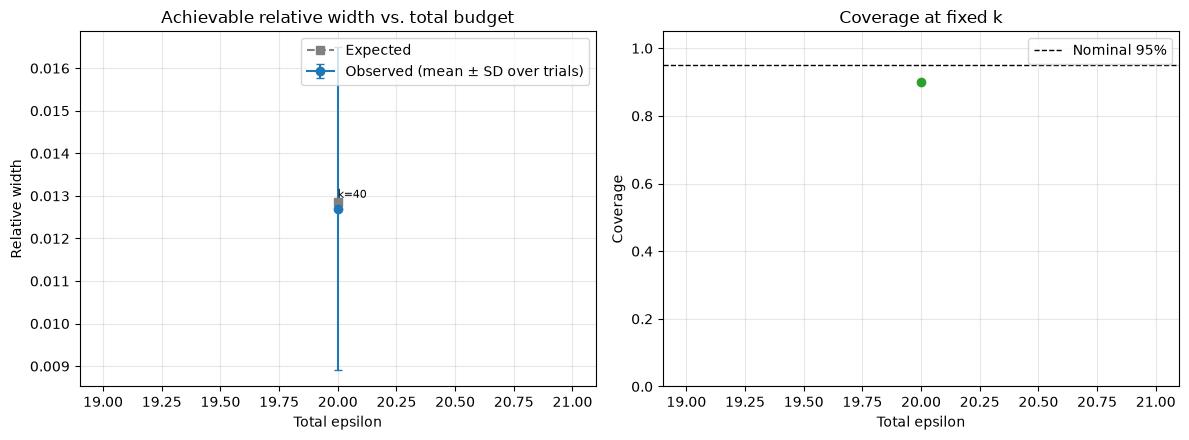

In [26]:
plot_rounds(hist_rounds)